In [1]:
!pip install ultralytics fastapi uvicorn python-multipart httpx pillow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 10.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [2]:
import torch

if torch.cuda.is_available():
    device = "cuda:0"
    print("GPU is available!")
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    device = "cpu"
    print("GPU is not available. Using CPU.")

print("Selected device:", device)

GPU is available!
GPU Name: Tesla T4
Selected device: cuda:0


In [3]:
from ultralytics import YOLO

# Load YOLO11 nano model
model = YOLO("yolo11n.pt")

print("YOLO model loaded successfully!")
print("Using device:", device)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
YOLO model loaded successfully!
Using device: cuda:0


In [4]:
from fastapi import FastAPI, UploadFile, File, HTTPException
from PIL import Image
import io

# Create FastAPI application
app = FastAPI(title="VisionPort Object Detection API")

print("VisionPort API created successfully!")

VisionPort API created successfully!


In [6]:
@app.get("/")
def home():
    return {
        "message": "Welcome to VisionPort",
        "status": "API is running"
    }

In [7]:
from collections import Counter

@app.post("/detect")
async def detect_objects(file: UploadFile = File(...)):

    # Check whether uploaded file is an image
    if not file.content_type or not file.content_type.startswith("image/"):
        raise HTTPException(
            status_code=400,
            detail="Please upload a valid image"
        )

    try:
        # Read uploaded image
        image_bytes = await file.read()

        # Convert uploaded bytes into an image
        image = Image.open(
            io.BytesIO(image_bytes)
        ).convert("RGB")

        # Perform object detection
        results = model.predict(
            source=image,
            conf=0.25,
            device=device
        )

        result = results[0]

        detections = []

        # Extract detected objects
        for box in result.boxes:

            class_id = int(box.cls[0])

            object_name = result.names[class_id]

            confidence = float(box.conf[0])

            coordinates = box.xyxy[0].tolist()

            detections.append({
                "object": object_name,
                "confidence": round(confidence * 100, 2),
                "bounding_box": [
                    round(value, 2) for value in coordinates
                ]
            })

        # Count each object category
        object_counts = dict(
            Counter(item["object"] for item in detections)
        )

        # Return detection results
        return {
            "filename": file.filename,
            "total_objects": len(detections),
            "object_counts": object_counts,
            "detections": detections
        }

    except HTTPException:
        raise

    except Exception as e:
        raise HTTPException(
            status_code=400,
            detail=f"Unable to process image: {str(e)}"
        )

In [8]:
from fastapi.testclient import TestClient

# Create test client
client = TestClient(app)

# Test home endpoint
response = client.get("/")

print("Status Code:", response.status_code)
print("Response:", response.json())

Status Code: 200
Response: {'message': 'Welcome to VisionPort', 'status': 'API is running'}


In [14]:
from google.colab import files

# Upload image
uploaded = files.upload()

# Get uploaded filename
filename = next(iter(uploaded.keys()))

# Send image to FastAPI detection endpoint
with open(filename, "rb") as image_file:

    response = client.post(
        "/detect",
        files={
            "file": (
                filename,
                image_file,
                "image/jpeg"
            )
        }
    )

# Display API response
print("Status Code:", response.status_code)

data = response.json()

print("\nVISIONPORT DETECTION RESULTS")
print("--------------------------------")

print("Filename:", data.get("filename"))
print("Total Objects:", data.get("total_objects"))

print("\nObject-wise Count:")

for name, count in data.get("object_counts", {}).items():
    print(name, ":", count)

print("\nIndividual Detections:")

for detection in data.get("detections", []):
    print(detection)

Saving images (3).jpg to images (3).jpg

0: 384x640 7 persons, 3 cars, 9 traffic lights, 1 backpack, 23.0ms
Speed: 2.3ms preprocess, 23.0ms inference, 1.5ms postprocess per image at shape (1, 3, 384, 640)
Status Code: 200

VISIONPORT DETECTION RESULTS
--------------------------------
Filename: images (3).jpg
Total Objects: 20

Object-wise Count:
person : 7
car : 3
traffic light : 9
backpack : 1

Individual Detections:
{'object': 'person', 'confidence': 91.54, 'bounding_box': [292.77, 147.15, 392.97, 386.52]}
{'object': 'person', 'confidence': 85.31, 'bounding_box': [204.13, 158.12, 236.15, 254.58]}
{'object': 'person', 'confidence': 84.01, 'bounding_box': [445.41, 154.6, 520.61, 367.09]}
{'object': 'person', 'confidence': 80.59, 'bounding_box': [71.69, 148.66, 149.17, 385.21]}
{'object': 'person', 'confidence': 79.88, 'bounding_box': [598.89, 144.73, 676.11, 381.47]}
{'object': 'car', 'confidence': 72.7, 'bounding_box': [0.12, 208.36, 102.2, 267.43]}
{'object': 'traffic light', 'confid


image 1/1 /content/images (3).jpg: 384x640 7 persons, 3 cars, 9 traffic lights, 1 backpack, 20.5ms
Speed: 1.8ms preprocess, 20.5ms inference, 1.5ms postprocess per image at shape (1, 3, 384, 640)


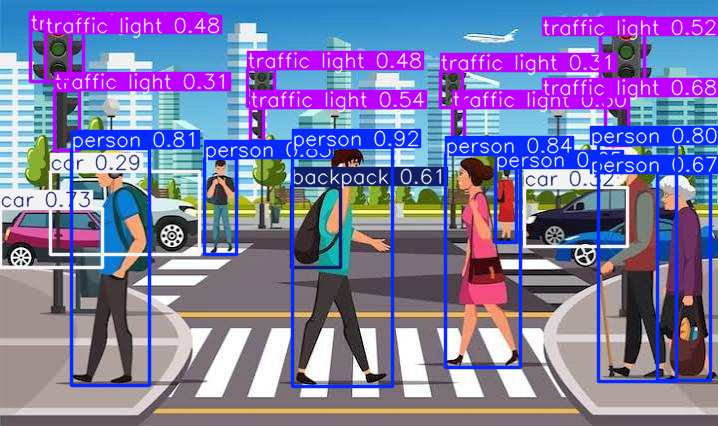

In [15]:
from IPython.display import display

# Run YOLO on the uploaded image
results = model.predict(
    source=filename,
    conf=0.25,
    device=device
)

# Get image with bounding boxes
annotated_image = results[0].plot()

# Convert BGR to RGB and display
display(
    Image.fromarray(annotated_image[:, :, ::-1])
)

In [16]:
print("========== VISIONPORT SUMMARY ==========")

print("Image:", filename)

print("Total Objects Detected:", data["total_objects"])

print("\nDetected Object Categories:")

for name, count in data["object_counts"].items():
    print(f"{name}: {count}")

print("\nDetection Details:")

for i, item in enumerate(data["detections"], start=1):

    print(f"\nObject {i}")
    print("Name:", item["object"])
    print("Confidence:", item["confidence"], "%")
    print("Bounding Box:", item["bounding_box"])

print("\n========== DETECTION COMPLETED ==========")

========== VISIONPORT SUMMARY ==========
Image: images (3).jpg
Total Objects Detected: 20

Detected Object Categories:
person: 7
car: 3
traffic light: 9
backpack: 1

Detection Details:

Object 1
Name: person
Confidence: 91.54 %
Bounding Box: [292.77, 147.15, 392.97, 386.52]

Object 2
Name: person
Confidence: 85.31 %
Bounding Box: [204.13, 158.12, 236.15, 254.58]

Object 3
Name: person
Confidence: 84.01 %
Bounding Box: [445.41, 154.6, 520.61, 367.09]

Object 4
Name: person
Confidence: 80.59 %
Bounding Box: [71.69, 148.66, 149.17, 385.21]

Object 5
Name: person
Confidence: 79.88 %
Bounding Box: [598.89, 144.73, 676.11, 381.47]

Object 6
Name: car
Confidence: 72.7 %
Bounding Box: [0.12, 208.36, 102.2, 267.43]

Object 7
Name: traffic light
Confidence: 68.39 %
Bounding Box: [605.56, 96.02, 628.71, 145.77]

Object 8
Name: person
Confidence: 66.55 %
Bounding Box: [657.8, 173.34, 710.18, 380.62]

Object 9
Name: person
Confidence: 64.77 %
Bounding Box: [495.43, 168.75, 516.83, 242.49]

Object 1